In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
from scipy import stats
from IPython.display import display
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
TASK = Path.cwd().parent
ROOT = TASK.parent
INPUT, OUTPUT = TASK/'input', TASK/'output'
CONFIG = json.loads((ROOT/'config.json').read_text())
EPS, Y, SEED = CONFIG['eps'], CONFIG['last_year'], CONFIG['seed']

In [3]:
sns.set_theme(style='whitegrid',context='notebook',palette='colorblind')
SELECTED = CONFIG['models']
ORDER = ['empirical_complete'] + SELECTED
PALETTE = dict(zip(ORDER,sns.color_palette('colorblind',len(ORDER))))
DASHES = dict(zip(ORDER,['',(4,2),(1,1),(6,2,1,2),(3,1,1,1),(8,2)]))
MARKERS = dict(zip(ORDER,['o','s','^','D','v','P']))
def save(fig,name):
    fig.tight_layout()
    fig.savefig(OUTPUT/(name+'.png'),dpi=180,bbox_inches='tight')
    fig.savefig(OUTPUT/(name+'.pdf'),bbox_inches='tight')
    plt.show()
    plt.close(fig)
def lines(data,x,y,ax):
    sns.lineplot(data=data,x=x,y=y,hue='source',style='source',hue_order=ORDER,style_order=ORDER,
                 palette=PALETTE,dashes=DASHES,markers=MARKERS,markersize=3,errorbar=None,ax=ax)
def legend(ax):
    ax.legend(fontsize=7,ncol=2)
def cdf_lines(data,x,y,ax):
    # duplicate x values draw vertical jumps; no averaging of left/right ECDF limits
    for source in ORDER:
        d = data.loc[data.source.eq(source)].sort_values(x,kind='stable')
        sns.lineplot(data=d,x=x,y=y,estimator=None,sort=False,color=PALETTE[source],
                     linestyle='-' if not DASHES[source] else (0,DASHES[source]),label=source,ax=ax)
    ax.set_ylim(-.02,1.02)

In [4]:
fits = pd.read_csv(INPUT/'increment_fits.csv',dtype={'stage':str})
hist = pd.read_csv(INPUT/'increment_histograms.csv',dtype={'stage':str})
qq = pd.read_csv(INPUT/'window_qq_points.csv')
qq_summary = pd.read_csv(INPUT/'window_qq_summary.csv')
loghist = pd.read_csv(INPUT/'total_log2_histograms.csv')

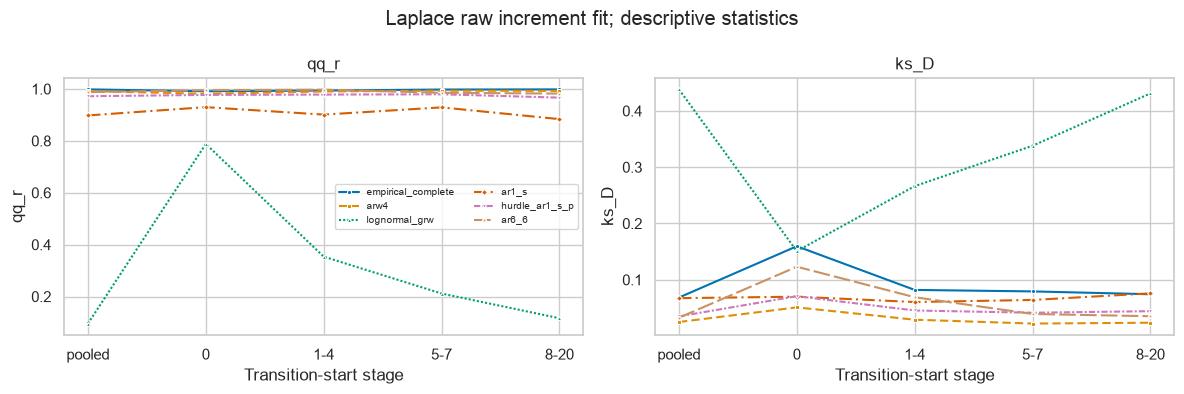

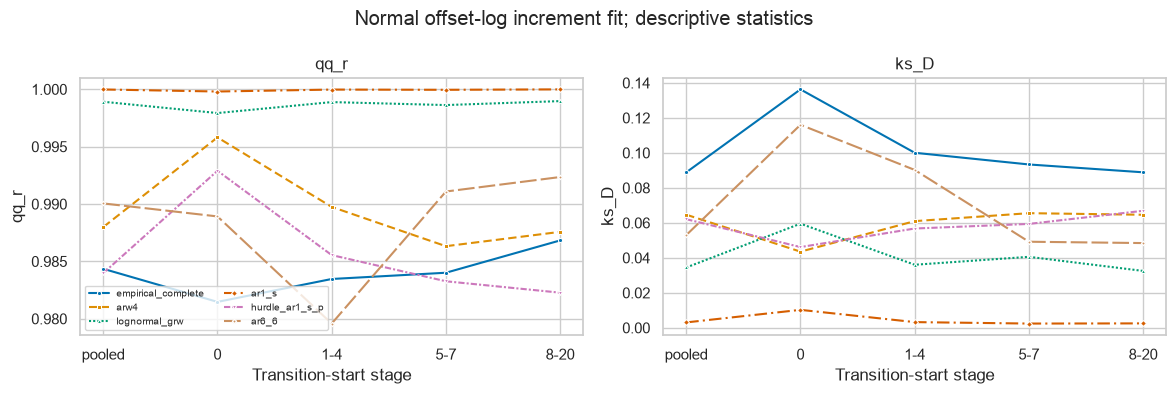

In [5]:
for scale in ['raw','offset_log']:
    subset = fits.loc[fits.scale.eq(scale)&fits.source.isin(ORDER)].copy()
    stages = ['pooled','0','1-4','5-7','8-20']
    subset['stage_index'] = subset.stage.map(dict(zip(stages,range(len(stages)))))
    fig,axes = plt.subplots(1,2,figsize=(12,4))
    for ax,metric in zip(axes,['qq_r','ks_D']):
        lines(subset,'stage_index',metric,ax)
        ax.set_xticks(range(len(stages)),stages)
        ax.set(xlabel='Transition-start stage',ylabel=metric,title=metric)
        if ax!=axes[0]:ax.legend().remove()
    legend(axes[0])
    fig.suptitle(('Laplace raw' if scale=='raw' else 'Normal offset-log')+' increment fit; descriptive statistics')
    save(fig,f'increment_fit_{scale}')

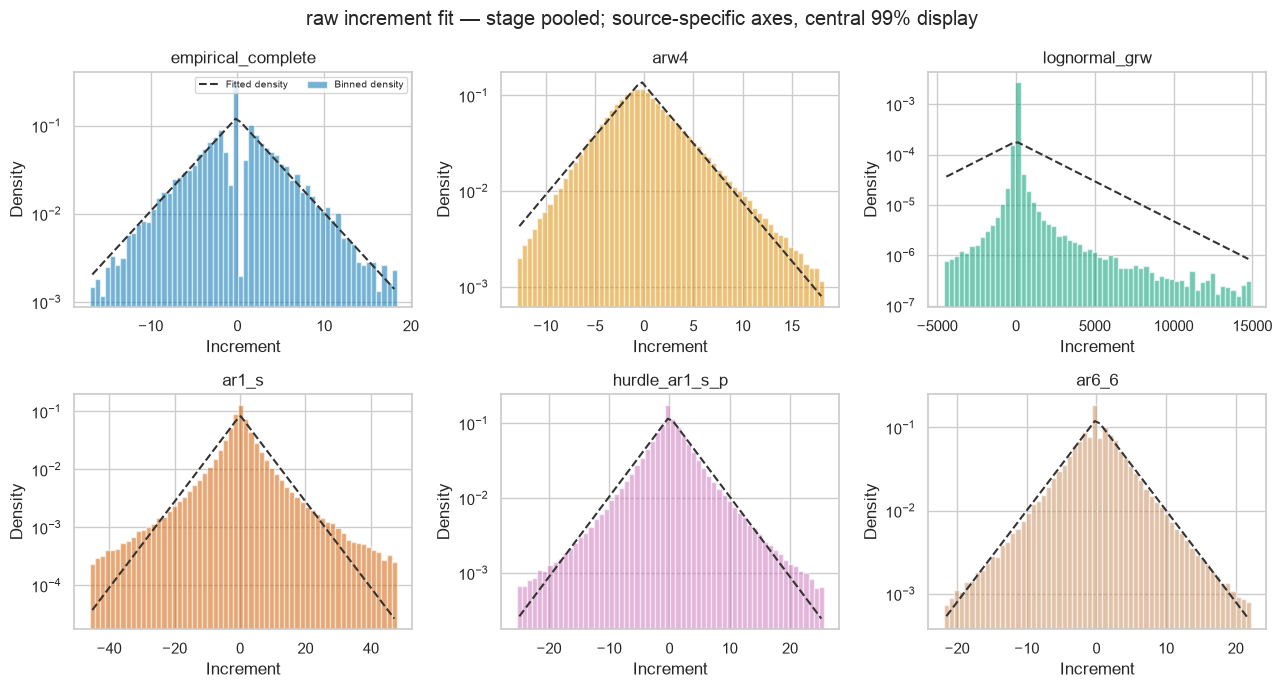

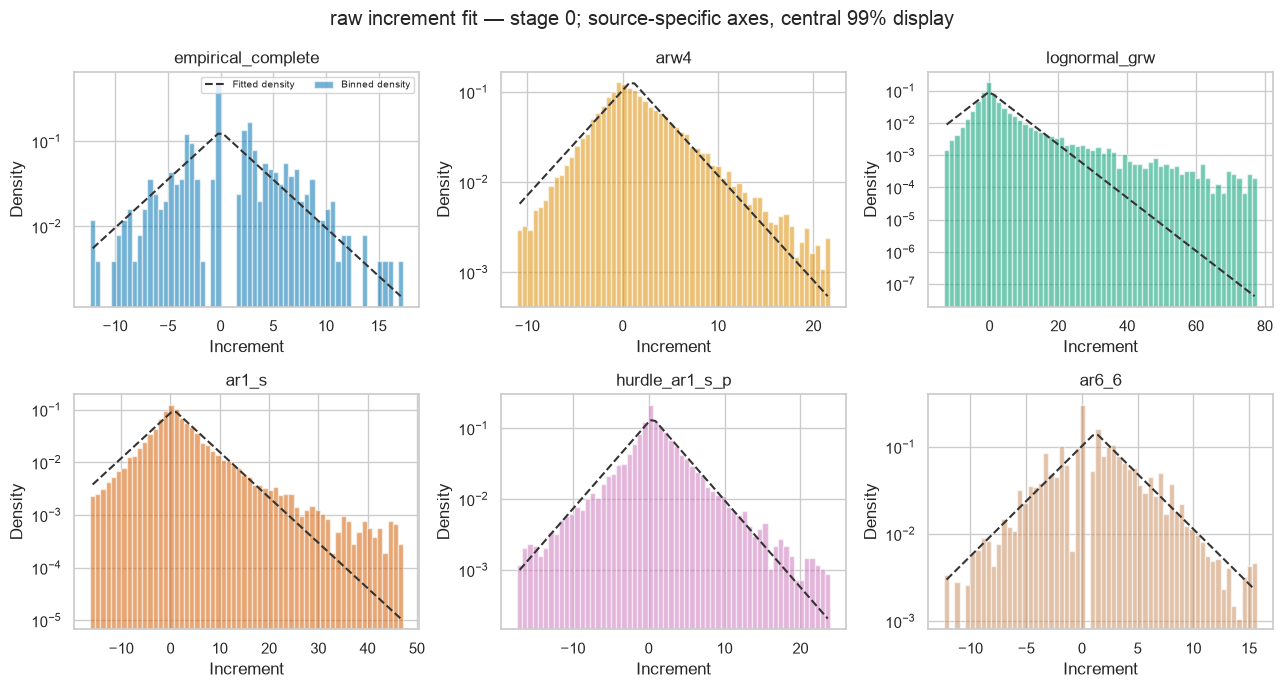

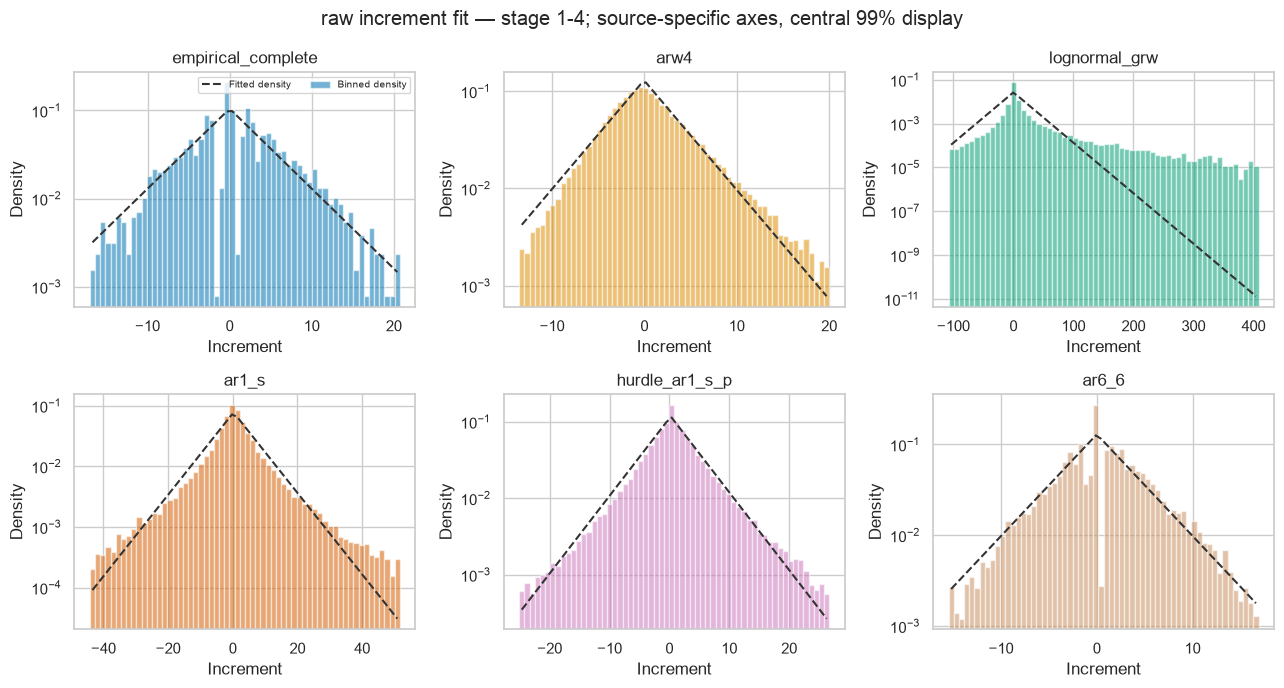

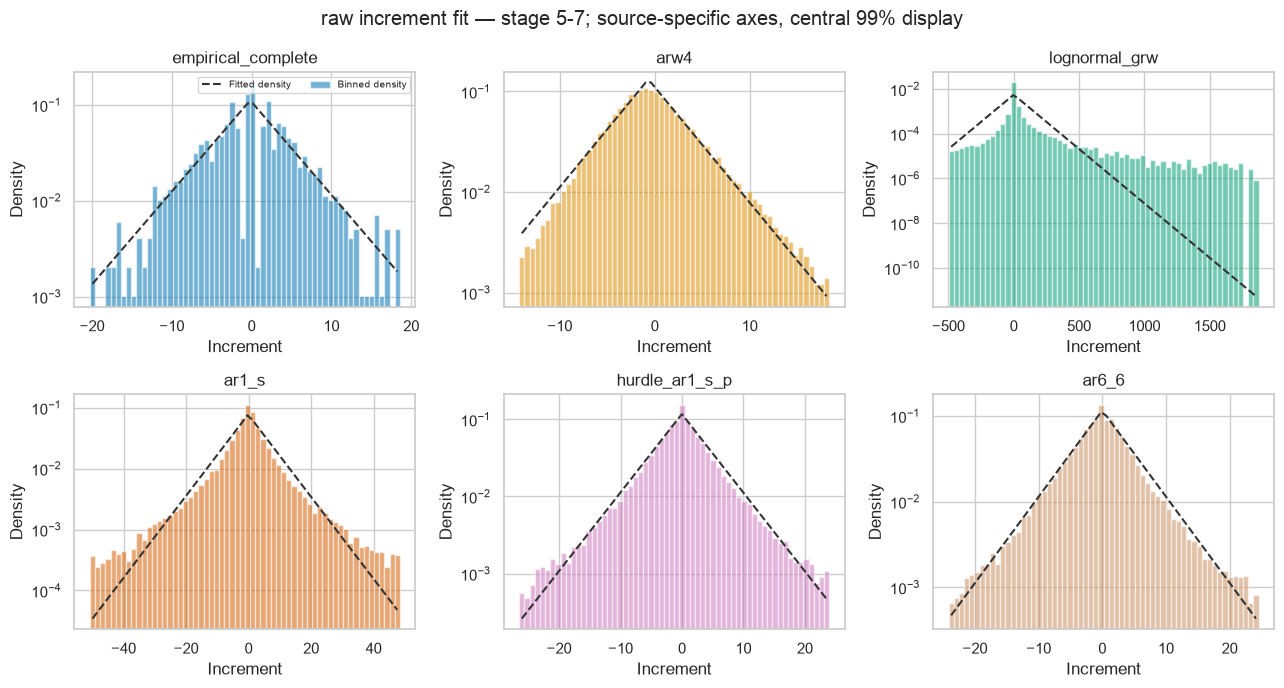

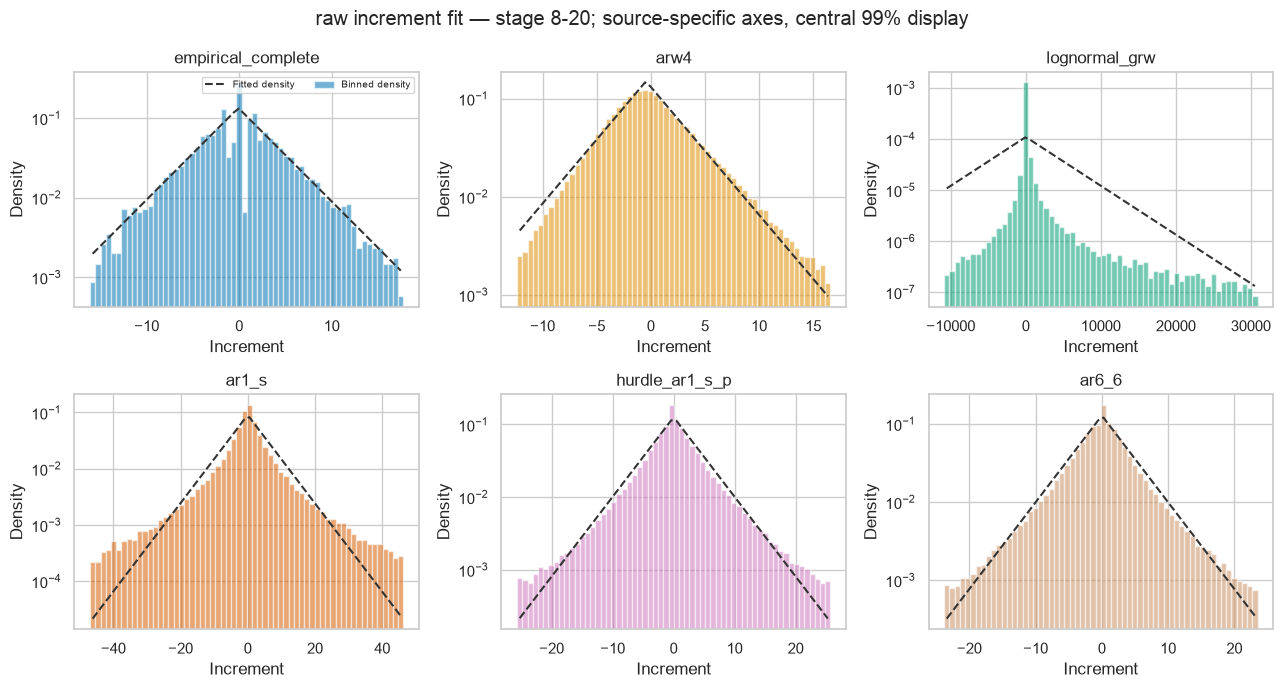

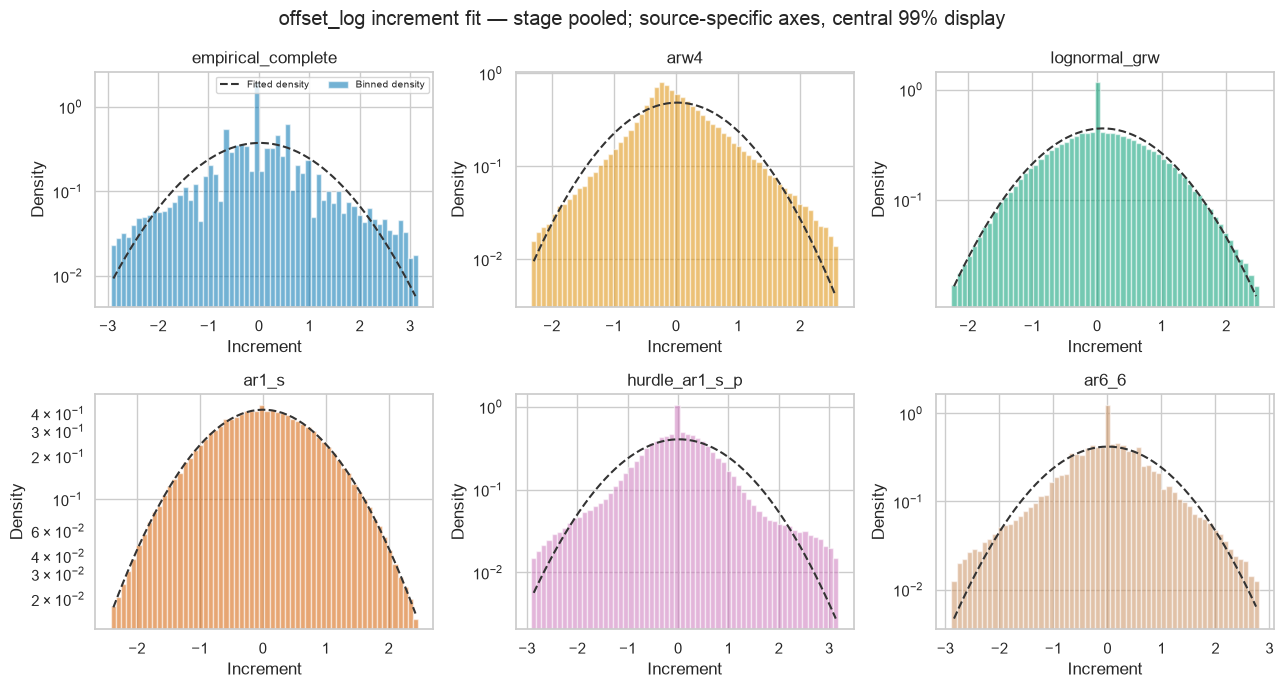

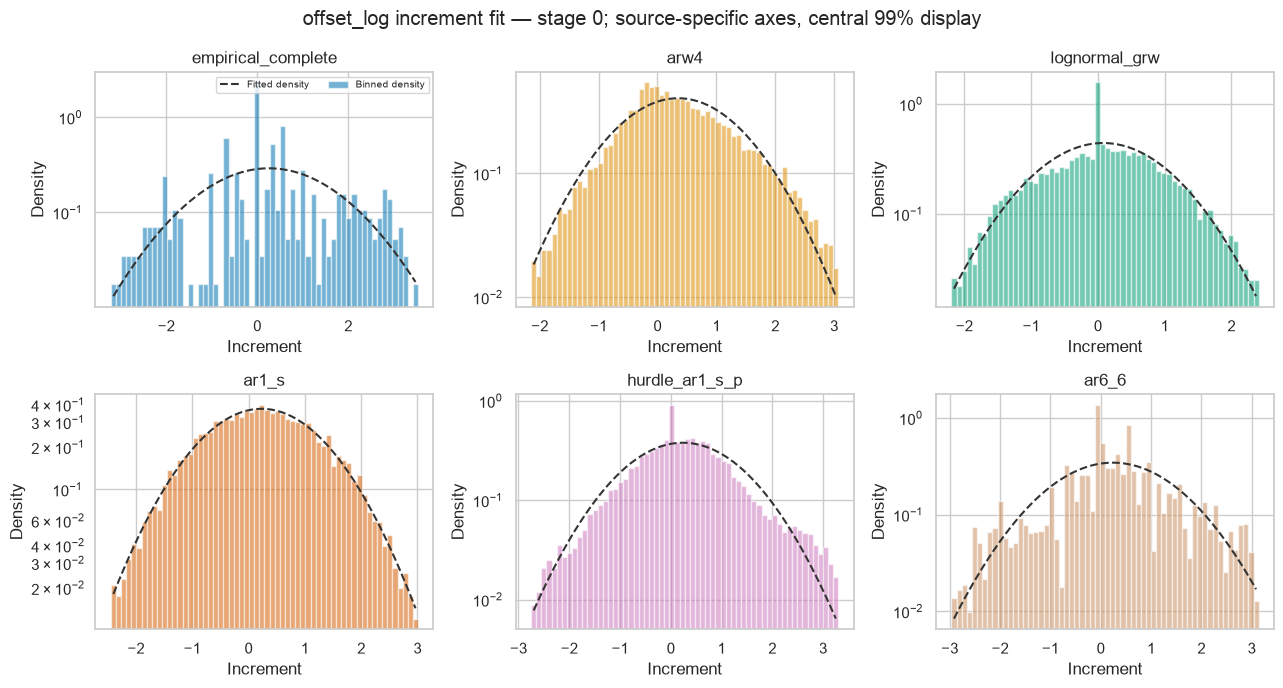

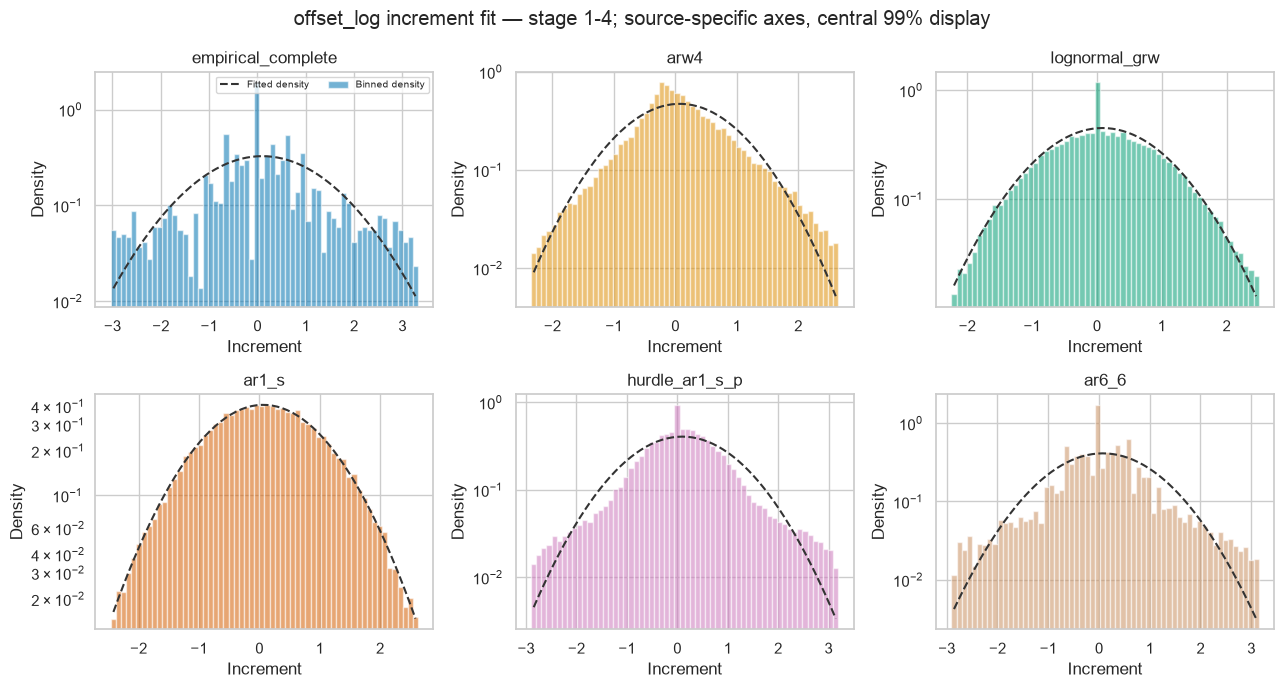

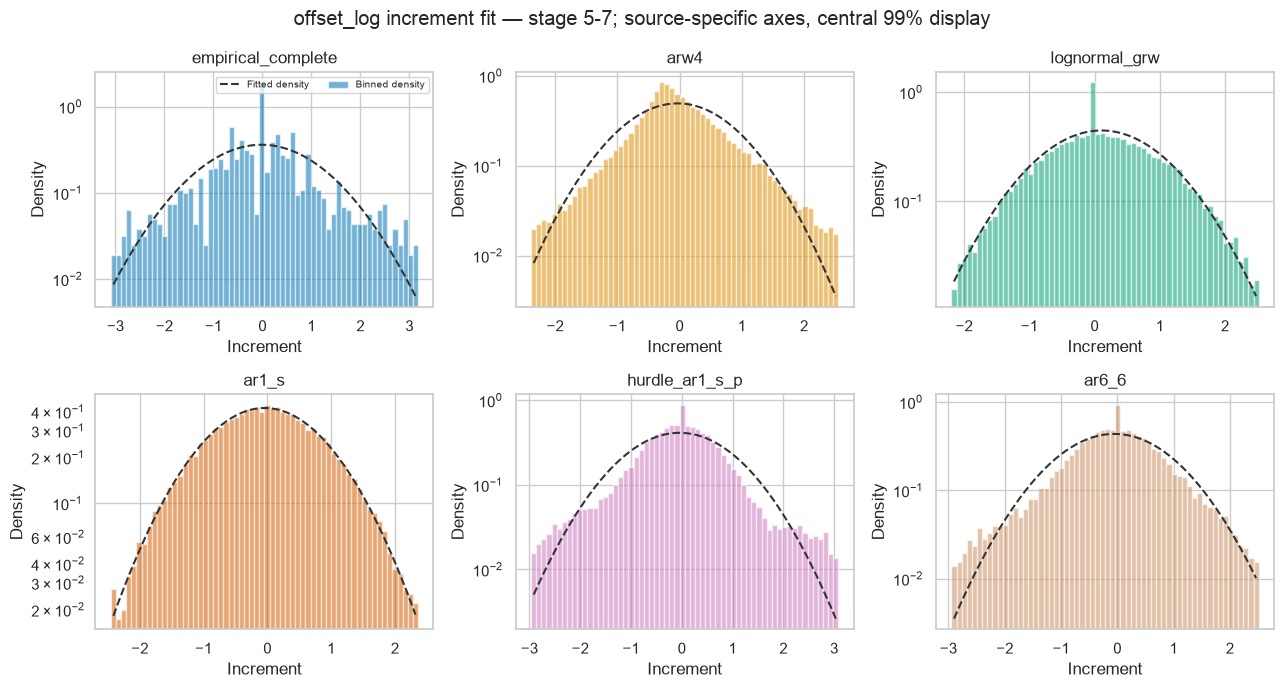

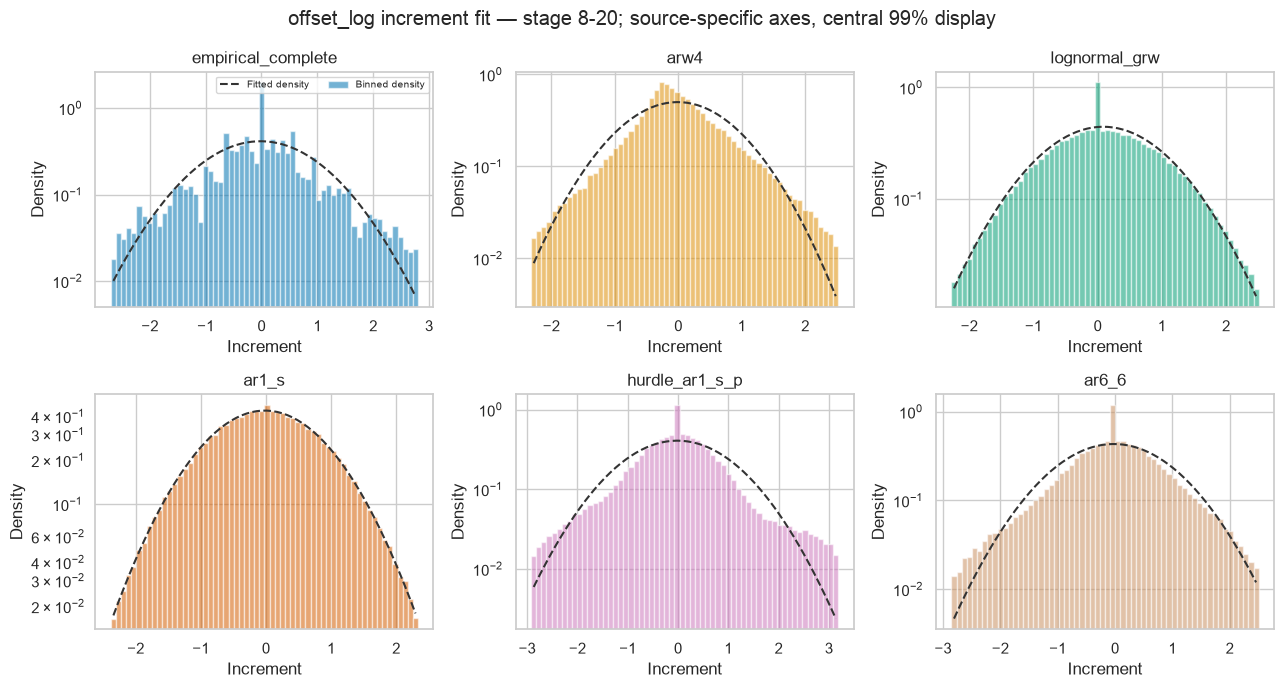

In [6]:
# per-source central-99% display; density is divided by full N, never renormalized after truncation
for scale in ['raw','offset_log']:
    for stage in ['pooled','0','1-4','5-7','8-20']:
        fig,axes = plt.subplots(2,3,figsize=(13,7))
        for ax,source in zip(axes.flat,ORDER):
            d = hist.loc[hist.source.eq(source)&hist.scale.eq(scale)&hist.stage.eq(stage)]
            ax.bar(d.x,d.density,width=d.width,color=PALETTE[source],alpha=.55,label='Binned density')
            sns.lineplot(data=d,x='x',y='fit_density',color='.2',linestyle='--',ax=ax,label='Fitted density')
            ax.set_yscale('log')
            ax.set(title=source,xlabel='Increment',ylabel='Density')
            if ax!=axes.flat[0]:ax.legend().remove()
        legend(axes.flat[0])
        fig.suptitle(f'{scale} increment fit — stage {stage}; source-specific axes, central 99% display')
        save(fig,f'increment_hist_{scale}_{stage}')

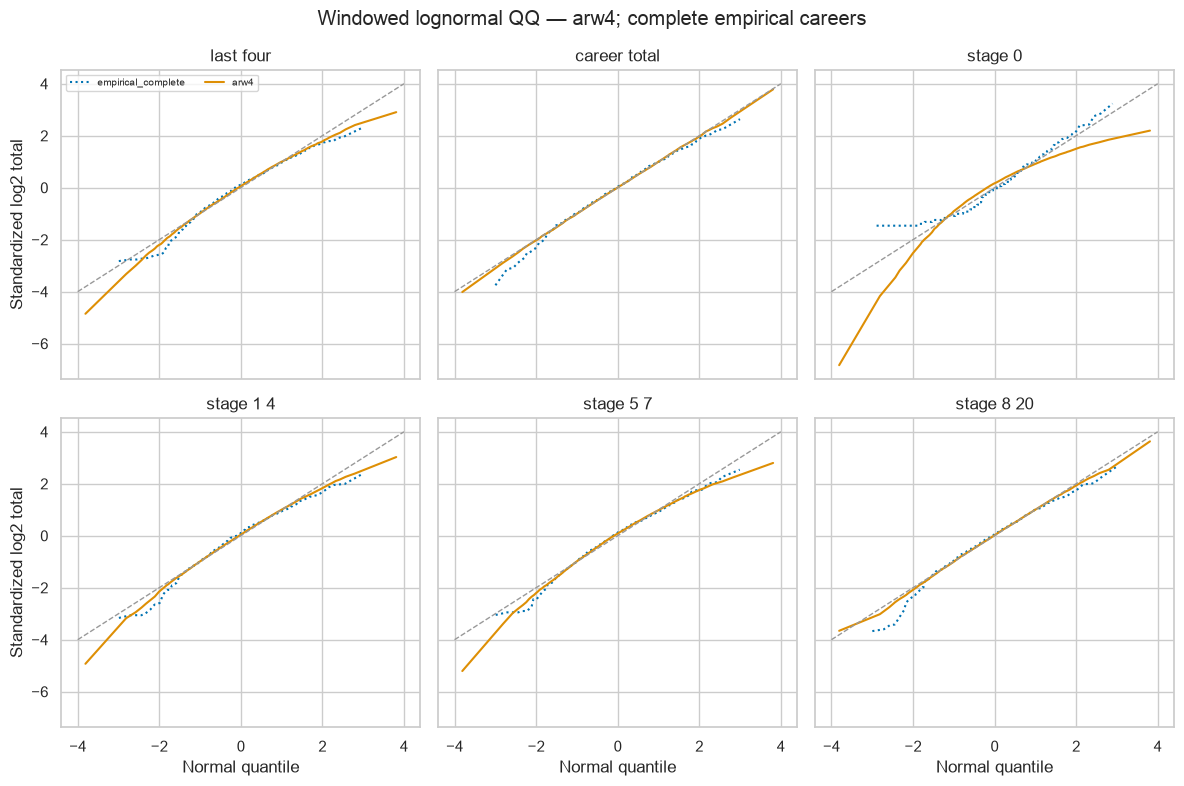

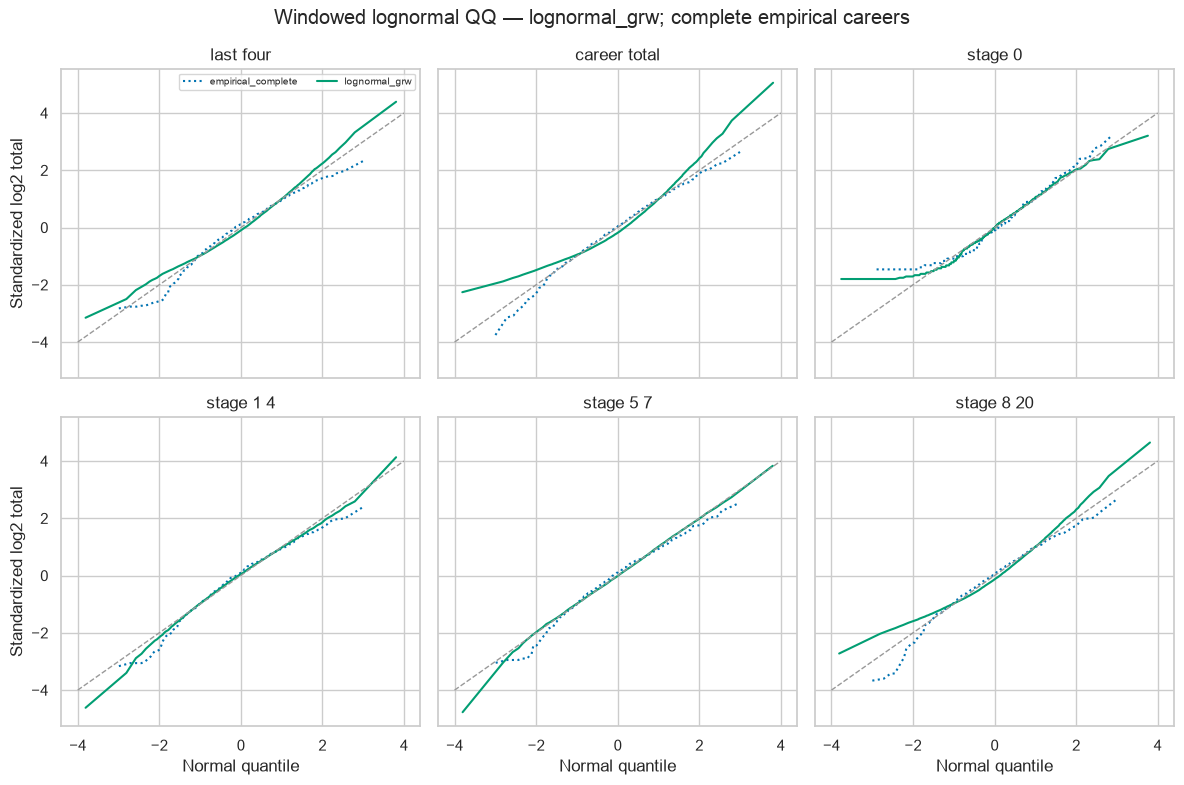

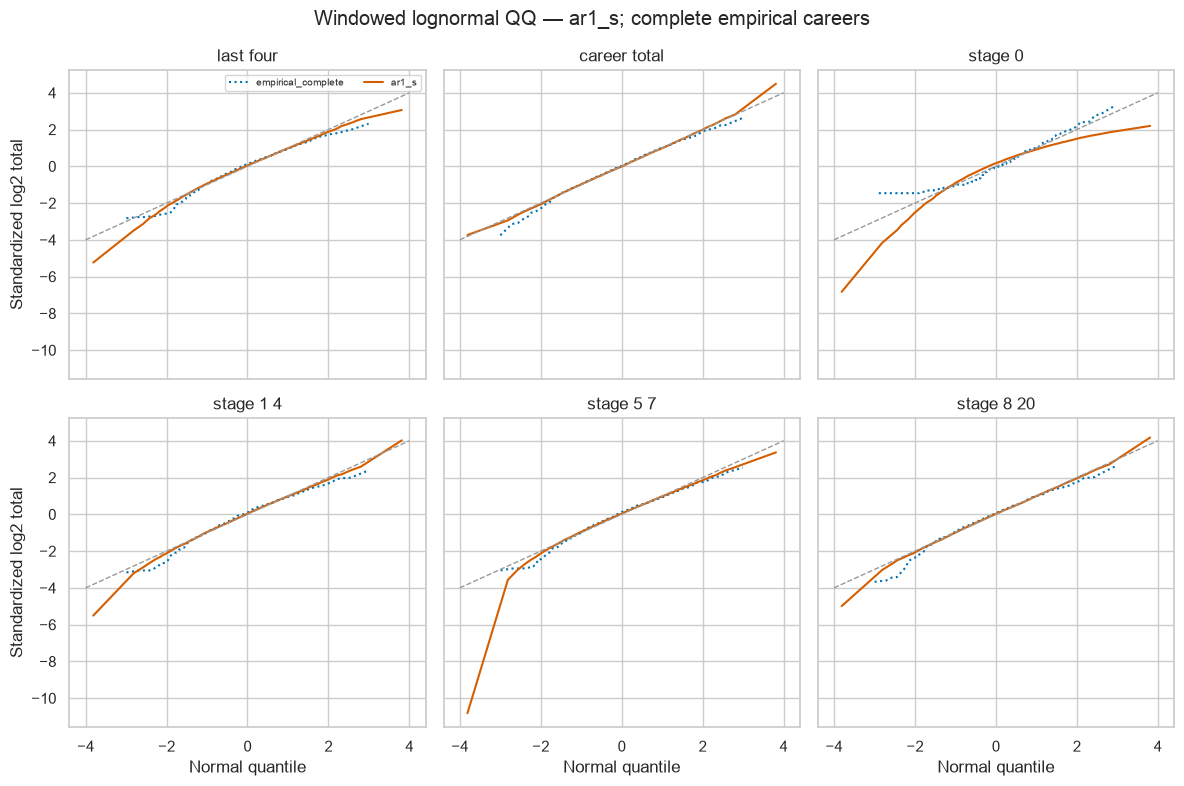

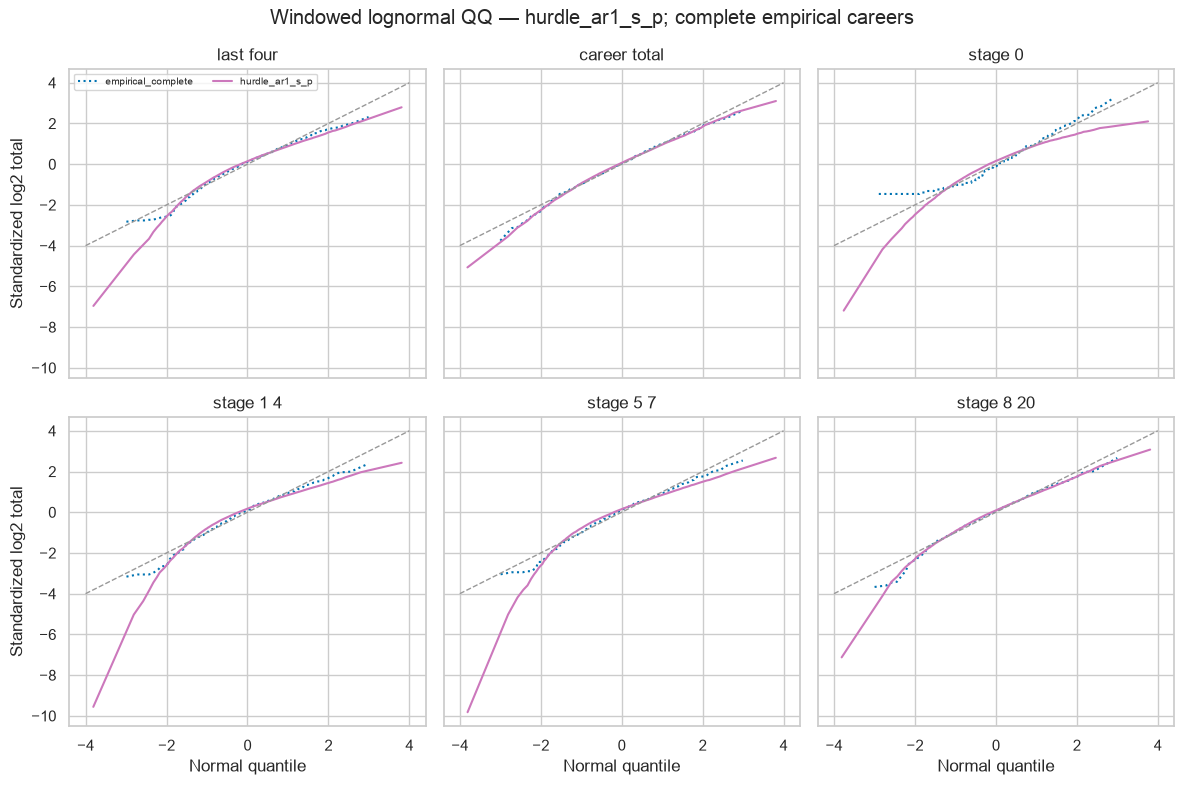

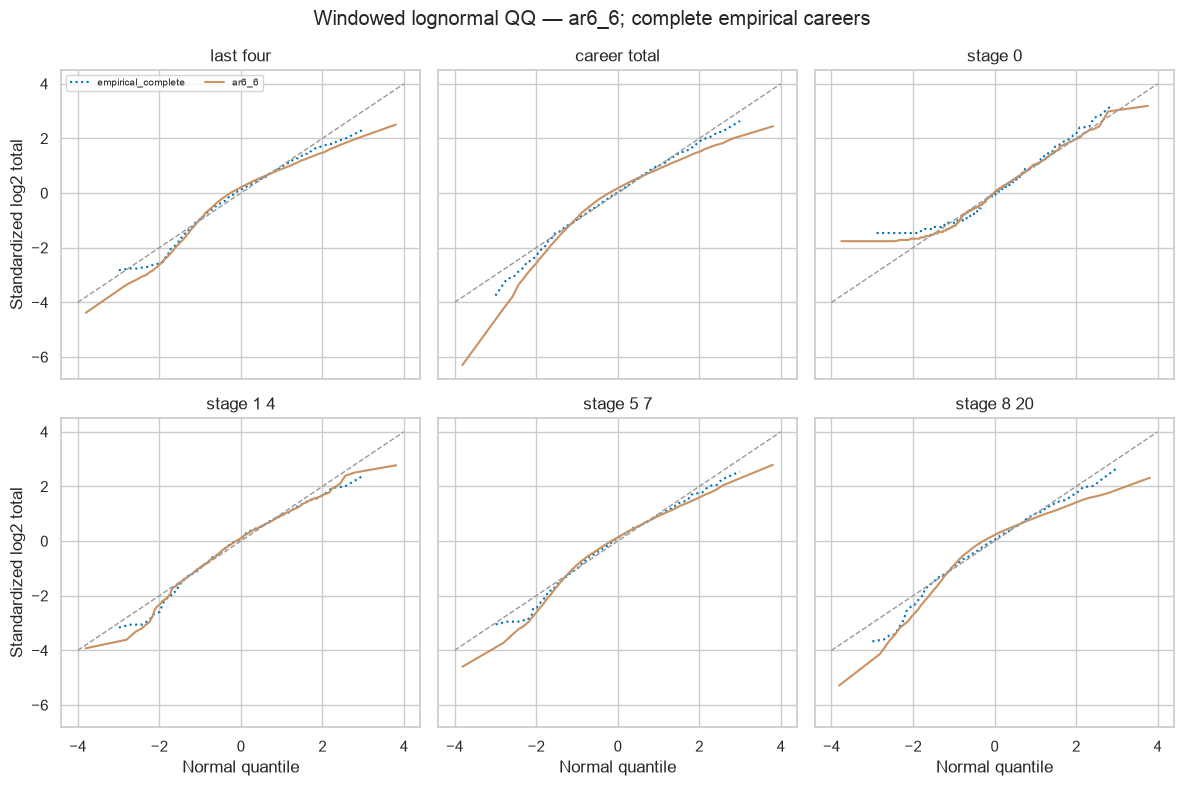

In [7]:
windows = ['last_four','career_total','stage_0','stage_1_4','stage_5_7','stage_8_20']
for tag in SELECTED:
    fig,axes = plt.subplots(2,3,figsize=(12,8),sharex=True,sharey=True)
    for ax,window in zip(axes.flat,windows):
        for source in ['empirical_complete',tag]:
            d = qq.loc[qq.source.eq(source)&qq.window.eq(window)]
            sns.lineplot(data=d,x='normal_quantile',y='observed_quantile',color=PALETTE[source],
                         linestyle=':' if source=='empirical_complete' else '-',ax=ax,label=source)
        ax.plot([-4,4],[-4,4],color='.6',ls='--',lw=1)
        ax.set(title=window.replace('_',' '),xlabel='Normal quantile',ylabel='Standardized log2 total')
        if ax!=axes.flat[0]:ax.legend().remove()
    legend(axes.flat[0])
    fig.suptitle(f'Windowed lognormal QQ — {tag}; complete empirical careers')
    save(fig,f'qq_windows_{tag}')

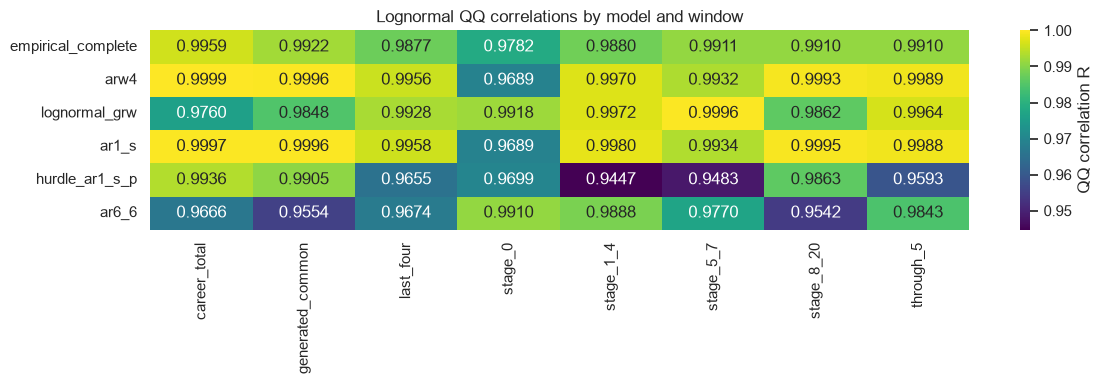

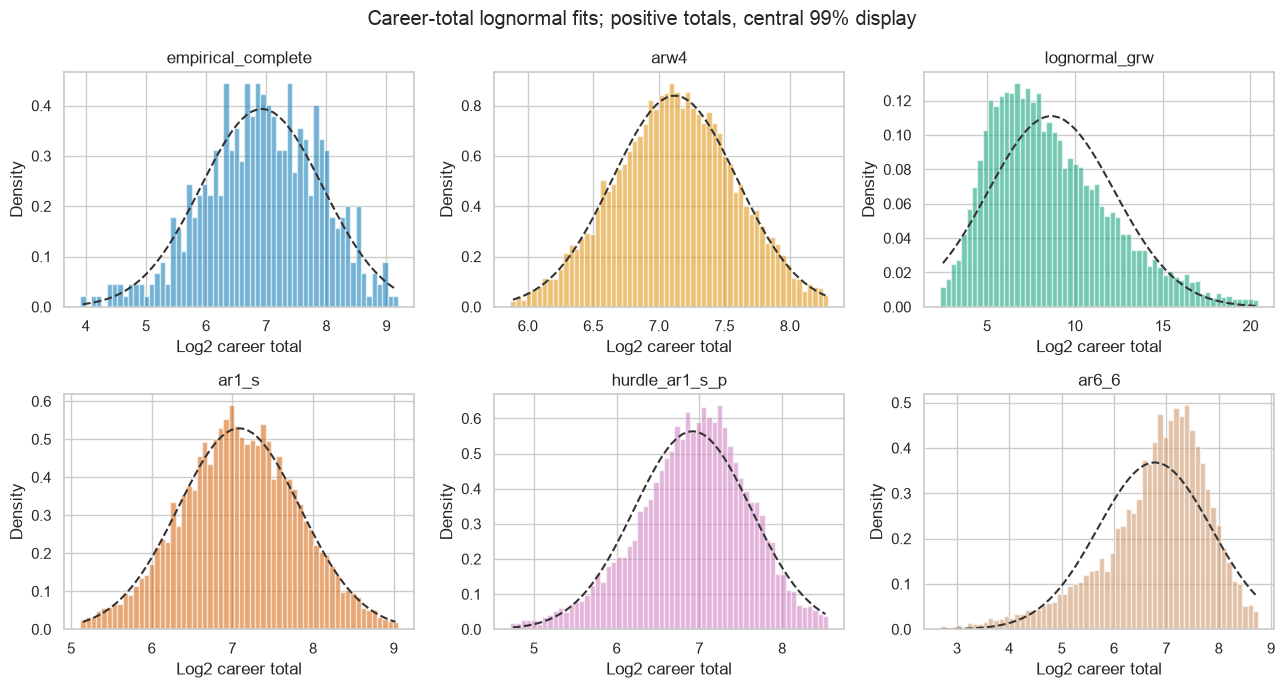

In [8]:
matrix = qq_summary.loc[qq_summary.source.isin(ORDER)].pivot(index='source',columns='window',values='qq_r').reindex(index=ORDER)
fig,ax = plt.subplots(figsize=(12,4))
sns.heatmap(matrix,annot=True,fmt='.4f',cmap='viridis',vmax=1,ax=ax,cbar_kws={'label':'QQ correlation R'})
ax.set(xlabel='',ylabel='',title='Lognormal QQ correlations by model and window')
save(fig,'qq_window_heatmap')
fig,axes = plt.subplots(2,3,figsize=(13,7))
for ax,source in zip(axes.flat,ORDER):
    d = loghist.loc[loghist.source.eq(source)&loghist.window.eq('career_total')]
    ax.bar(d.x,d.density,width=d.width,color=PALETTE[source],alpha=.55)
    sns.lineplot(data=d,x='x',y='fit_density',color='.2',linestyle='--',ax=ax)
    ax.set(title=source,xlabel='Log2 career total',ylabel='Density')
fig.suptitle('Career-total lognormal fits; positive totals, central 99% display')
save(fig,'cumulative_lognormal_histograms')